# Edge deployment: VisDrone modelini dronda işləməyə hazırlamaq

**Sual:** öyrətdiyimiz `best.pt` modelini daha kiçik və sürətli formatlara çevirsək, sürət nə qədər artır və dəqiqlik nə qədər düşür?

Müqayisə olunan variantlar:
| Variant | Nə edir |
|---|---|
| PyTorch FP32 | başlanğıc model (GPU və CPU-da) |
| PyTorch FP16 | yarım dəqiqlik, GPU-da |
| ONNX FP32 | portativ format (Jetson, Raspberry Pi, brauzer və s.) |
| ONNX INT8 (tam) | bütün Conv qatları 8-bit tam ədədlə, ölçü ~4 dəfə kiçik |
| ONNX INT8 (başlıq FP32) | detection başlığı dəqiq qalır, qalanı INT8 (adətən dəqiqliyi daha yaxşı saxlayır) |

**Əvvəlcə:** Runtime → **T4 GPU** (FP16 və GPU müqayisəsi üçün). CPU ölçmələri Colab-ın CPU-sunda aparılır.

**Vacib:** Colab CPU-su (2 nüvə) real dron kompüteri deyil. Nəticələri **nisbi müqayisə** kimi (neçə dəfə sürətli, mAP nə qədər düşdü) göstər, mütləq FPS-i isə "Colab CPU" qeydi ilə yaz.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
WEIGHTS = "/content/drive/MyDrive/yolo_runs/visdrone_yolov8s_960/weights/best.pt"
OUT_DIR = "/content/drive/MyDrive/yolo_runs/edge_benchmark"
IMGSZ   = 960      
N_VAL   = 200     
N_CALIB = 100      

os.makedirs(OUT_DIR, exist_ok=True)
assert os.path.exists(WEIGHTS), "best.pt tapılmadı: WEIGHTS yolunu yoxla"
print("best.pt ölçüsü:", round(os.path.getsize(WEIGHTS) / 1e6, 1), "MB")

Mounted at /content/drive
best.pt ölçüsü: 22.5 MB


In [2]:
!pip install -q ultralytics onnx

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 95.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 132.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 39.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 kB 14.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.


In [3]:
import os, re, time
import numpy as np
import cv2


def letterbox(img, size, color=114):
    h, w = img.shape[:2]
    r = min(size / h, size / w)
    nh, nw = int(round(h * r)), int(round(w * r))
    resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    top, left = (size - nh) // 2, (size - nw) // 2
    out = np.full((size, size, 3), color, np.uint8)
    out[top:top + nh, left:left + nw] = resized
    return out


def preprocess(path, size):
    img = cv2.imread(str(path))
    img = letterbox(img, size)
    x = img[:, :, ::-1].transpose(2, 0, 1)            
    x = np.ascontiguousarray(x, dtype=np.float32) / 255.0
    return x[None]


def model_size_mb(path):
    return os.path.getsize(path) / 1e6


def head_nodes(onnx_path):
    import onnx
    m = onnx.load(onnx_path)
    idx = []
    for n in m.graph.node:
        mt = re.match(r"^/model\.(\d+)/", n.name)
        if mt:
            idx.append(int(mt.group(1)))
    if not idx:
        return []
    last = max(idx)
    return [n.name for n in m.graph.node if n.name.startswith(f"/model.{last}/")]


def quantize_int8(fp32_path, out_path, calib_images, imgsz, keep_head_fp32=False):
  
    from onnxruntime.quantization import (CalibrationDataReader, QuantFormat, QuantType,
                                          quantize_static)
    pre_path = fp32_path.replace(".onnx", "_pre.onnx")
    try:
        from onnxruntime.quantization.shape_inference import quant_pre_process
        quant_pre_process(fp32_path, pre_path, skip_optimization=True, skip_symbolic_shape=True)
    except Exception as e:
        print("quant_pre_process atlandı:", repr(e)[:120])
        pre_path = fp32_path

    import onnxruntime as ort
    input_name = ort.InferenceSession(pre_path, providers=["CPUExecutionProvider"]).get_inputs()[0].name

    class Reader(CalibrationDataReader):
        def __init__(self):
            self.it = iter(calib_images)

        def get_next(self):
            p = next(self.it, None)
            return None if p is None else {input_name: preprocess(p, imgsz)}

    exclude = head_nodes(pre_path) if keep_head_fp32 else []
    if keep_head_fp32:
        print(f"FP32-də qalan node sayı (detection başlığı): {len(exclude)}")
        if not exclude:
            print("Node adları tanınmadı, başlıq ayrıla bilmədi (tam INT8 olacaq)")

    quantize_static(
        pre_path, out_path, Reader(),
        quant_format=QuantFormat.QDQ,
        per_channel=True,
        weight_type=QuantType.QInt8,
        activation_type=QuantType.QUInt8,
        op_types_to_quantize=["Conv"],
        nodes_to_exclude=exclude,
    )
    import onnx
    q = onnx.load(out_path)
    if len(q.metadata_props) == 0:
        for prop in onnx.load(fp32_path, load_external_data=False).metadata_props:
            m = q.metadata_props.add()
            m.key, m.value = prop.key, prop.value
        onnx.save(q, out_path)
    return out_path


def ort_latency(path, threads=0, runs=30, warmup=5):
    import onnxruntime as ort
    so = ort.SessionOptions()
    if threads:
        so.intra_op_num_threads = threads
    sess = ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])
    inp = sess.get_inputs()[0]
    shape = [d if isinstance(d, int) else 1 for d in inp.shape]
    x = np.random.rand(*shape).astype(np.float16 if "float16" in inp.type else np.float32)
    for _ in range(warmup):
        sess.run(None, {inp.name: x})
    ts = []
    for _ in range(runs):
        t = time.perf_counter()
        sess.run(None, {inp.name: x})
        ts.append((time.perf_counter() - t) * 1000)
    return float(np.median(ts)), float(np.percentile(ts, 95))


def build_table(rows):
    import pandas as pd
    df = pd.DataFrame(rows)
    base = df[(df["variant"] == "PyTorch FP32") & (df["device"] == "CPU")]
    if len(base):
        b = base.iloc[0]
        df["speedup_vs_PT_CPU"] = np.where(df["device"] == "CPU", (b["total_ms"] / df["total_ms"]).round(2), np.nan)
        df["mAP50-95_change"] = (df["mAP50-95"] - b["mAP50-95"]).round(3)
    return df


## Dataset və qiymətləndirmə üçün alt-çoxluq
- Qiymətləndirmə **eyni** şəkillərdə bütün variantlar üçün aparılır (ədalətli müqayisə).
- INT8 kalibrasiyası **təlim** şəkillərindən götürülür, qiymətləndirmə validasiya şəkillərində olur (kalibrasiya şəkilləri ilə test etmirik).

In [4]:
from glob import glob
import yaml
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("VisDrone.yaml")

def first(x):
    return x[0] if isinstance(x, (list, tuple)) else x

val_imgs   = sorted(glob(os.path.join(str(first(data["val"])), "*.jpg")))
train_imgs = sorted(glob(os.path.join(str(first(data["train"])), "*.jpg")))
print("val:", len(val_imgs), "| train:", len(train_imgs))

subset = val_imgs[::max(1, len(val_imgs) // N_VAL)][:N_VAL] if N_VAL else val_imgs
with open("/content/val_subset.txt", "w") as f:
    f.write("\n".join(subset))

DATA_YAML = "/content/visdrone_subset.yaml"
with open(DATA_YAML, "w") as f:
    yaml.safe_dump({"train": str(first(data["train"])), "val": "/content/val_subset.txt",
                    "names": data["names"]}, f)

calib_images = train_imgs[::max(1, len(train_imgs) // N_CALIB)][:N_CALIB]
print("qiymətləndirmə şəkli:", len(subset), "| kalibrasiya şəkli:", len(calib_images))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

WARNING ⚠️ Dataset 'VisDrone.yaml' images not found, missing path '/content/datasets/VisDrone/images/val'
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-val.zip to /content/datasets/VisDrone/VisDrone2019-DET-val...: 100% ━━━━━━━━━━━━ 1099/1099 474.0files/s 2.3s/s 1.2s<13.2s10.6s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-test-dev.zip to /content/datasets/VisDrone/VisDrone2019-DET-test-dev...: 100% ━━━━━━━━━━━━ 3223/3223 661.2files/s 4.9s.1ss<2.3s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-train.zip to /content/datasets/VisDrone/VisDrone2019-DET-train...: 100% ━━━━━━━━━━━━ 12945/12945 1.4Kfiles/s 9.0s<0.1s
Converting train: ━━━━━━━━━━━━ 6471 1.4Kit/s 3.9s
Converting val

## Qiymətləndirmə funksiyası
`batch=1` ilə ölçürük, çünki dronda kadrlar bir-bir gəlir. Sürət göstəriciləri: ön emal + model + son emal (NMS və s.) birlikdə (`total_ms`).

In [5]:
import torch
HAS_GPU = torch.cuda.is_available()
print("GPU var:", HAS_GPU)

results = []

def evaluate(label, weights, device, half=False, size=True):
    m = YOLO(weights, task="detect")
    r = m.val(data=DATA_YAML, imgsz=IMGSZ, batch=1, device=device, half=half,
              plots=False, verbose=False, project="/content/val_runs", name="tmp", exist_ok=True)
    sp = r.speed
    total = sp["preprocess"] + sp["inference"] + sp["postprocess"]
    row = {"variant": label, "device": "GPU (T4)" if device == 0 else "CPU",
           "size_MB": round(model_size_mb(weights), 1) if size else None,
           "mAP50": round(float(r.box.map50), 3), "mAP50-95": round(float(r.box.map), 3),
           "inference_ms": round(sp["inference"], 1), "total_ms": round(total, 1),
           "FPS": round(1000 / total, 1)}
    results.append(row)
    print(row)
    return row

GPU var: True


In [6]:
if HAS_GPU:
    evaluate("PyTorch FP32", WEIGHTS, device=0)
    evaluate("PyTorch FP16", WEIGHTS, device=0, half=True, size=False)
evaluate("PyTorch FP32", WEIGHTS, device="cpu")

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.189 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,454 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1877.7±364.7 MB/s, size: 153.6 KB)
val: Scanning /content/datasets/VisDrone/labels/val... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 1.4Kit/s 0.1s<0.1s
val: New cache created: /content/datasets/VisDrone/labels/val.cache
WARNING ⚠️ Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 200/200 38.3it/s 5.2s0.1s
          

{'variant': 'PyTorch FP32',
 'device': 'CPU',
 'size_MB': 22.5,
 'mAP50': 0.432,
 'mAP50-95': 0.26,
 'inference_ms': 494.8,
 'total_ms': 521.3,
 'FPS': 1.9}

In [7]:
exported = YOLO(WEIGHTS).export(format="onnx", imgsz=IMGSZ, simplify=True, dynamic=False)
ONNX_FP32 = "/content/best_fp32.onnx"
shutil.copy(exported, ONNX_FP32)
evaluate("ONNX FP32", ONNX_FP32, device="cpu")

Ultralytics 8.4.189 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 72 layers, 11,129,454 parameters, 0 gradients, 64.0 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/yolo_runs/visdrone_yolov8s_960/weights/best.pt' with input shape (1, 3, 960, 960) BCHW and output shape(s) (1, 14, 18900) (21.5 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 251ms
Prepared 3 packages in 480ms
Installed 3 packages in 14ms
 + colorama==0.4.6
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 2.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim

{'variant': 'ONNX FP32',
 'device': 'CPU',
 'size_MB': 45.0,
 'mAP50': 0.431,
 'mAP50-95': 0.26,
 'inference_ms': 774.1,
 'total_ms': 802.5,
 'FPS': 1.2}

In [8]:
ONNX_INT8       = "/content/best_int8.onnx"
ONNX_INT8_MIXED = "/content/best_int8_mixed.onnx"

quantize_int8(ONNX_FP32, ONNX_INT8, calib_images, IMGSZ, keep_head_fp32=False)
evaluate("ONNX INT8 (tam)", ONNX_INT8, device="cpu")

quantize_int8(ONNX_FP32, ONNX_INT8_MIXED, calib_images, IMGSZ, keep_head_fp32=True)
evaluate("ONNX INT8 (başlıq FP32)", ONNX_INT8_MIXED, device="cpu")

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.189 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
Loading /content/best_int8.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.0 with CPUExecutionProvider
Setting batch=1 input of shape (1, 3, 960, 960)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1993.5±301.1 MB/s, size: 126.5 KB)
val: Scanning /content/datasets/VisDrone/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 52.4Mit/s 0.0s
WARNING ⚠️ Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 200/200 1.4it/s 2:2

{'variant': 'ONNX INT8 (başlıq FP32)',
 'device': 'CPU',
 'size_MB': 18.2,
 'mAP50': 0.371,
 'mAP50-95': 0.218,
 'inference_ms': 744.5,
 'total_ms': 770.0,
 'FPS': 1.3}

## Yalnız model gecikməsi və nüvə sayı
Dron kompüterləri çox vaxt az nüvəlidir (məsələn, Raspberry Pi 4: 4 nüvə). Müxtəlif thread sayı ilə **yalnız model gecikməsini** (ön/son emalsız) ölçürük.

In [9]:
import pandas as pd
thread_list = sorted({1, 2, os.cpu_count() or 2})
lat_rows = []
for name, p in [("ONNX FP32", ONNX_FP32), ("ONNX INT8 (tam)", ONNX_INT8), ("ONNX INT8 (başlıq FP32)", ONNX_INT8_MIXED)]:
    for t in thread_list:
        med, p95 = ort_latency(p, threads=t, runs=20, warmup=3)
        lat_rows.append({"variant": name, "threads": t, "median_ms": round(med, 1), "p95_ms": round(p95, 1),
                         "FPS": round(1000 / med, 2)})
lat_df = pd.DataFrame(lat_rows)
lat_df

,variant,threads,median_ms,p95_ms,FPS
0,ONNX FP32,1,694.9,1016.3,1.44
1,ONNX FP32,2,711.6,1198.1,1.41
2,ONNX INT8 (tam),1,634.8,818.3,1.58
3,ONNX INT8 (tam),2,599.2,988.5,1.67
4,ONNX INT8 (başlıq FP32),1,683.0,894.2,1.46
5,ONNX INT8 (başlıq FP32),2,672.5,1127.3,1.49


,variant,device,size_MB,mAP50,mAP50-95,inference_ms,total_ms,FPS,speedup_vs_PT_CPU,mAP50-95_change
0,PyTorch FP32,GPU (T4),22.5,0.432,0.260,11.4,15.8,63.3,NaN,0.000
1,PyTorch FP16,GPU (T4),NaN,0.431,0.260,16.0,20.8,48.0,NaN,0.000
2,PyTorch FP32,CPU,22.5,0.432,0.260,494.8,521.3,1.9,1.00,0.000
3,ONNX FP32,CPU,45.0,0.431,0.260,774.1,802.5,1.2,0.65,0.000
4,ONNX INT8 (tam),CPU,11.9,0.366,0.213,667.9,694.9,1.4,0.75,-0.047
5,ONNX INT8 (başlıq FP32),CPU,18.2,0.371,0.218,744.5,770.0,1.3,0.68,-0.042


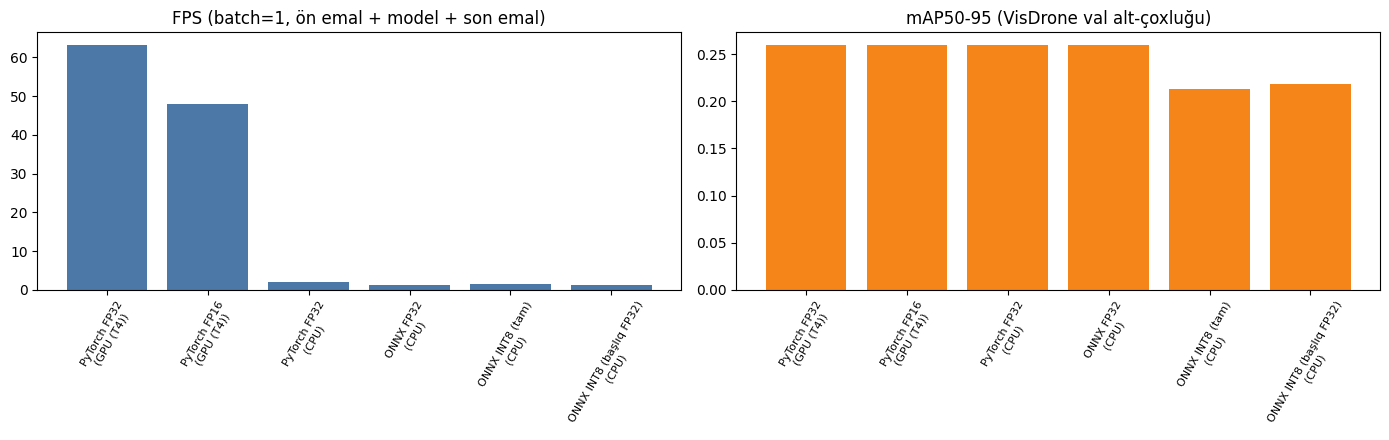

In [10]:
import matplotlib.pyplot as plt

df = build_table(results)
display(df)
df.to_csv(f"{OUT_DIR}/results.csv", index=False)
lat_df.to_csv(f"{OUT_DIR}/latency_by_threads.csv", index=False)

labels = [f"{v}\n({d})" for v, d in zip(df["variant"], df["device"])]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(labels, df["FPS"], color="#4C78A8"); axes[0].set_title("FPS (batch=1, ön emal + model + son emal)")
axes[1].bar(labels, df["mAP50-95"], color="#F58518"); axes[1].set_title("mAP50-95 (VisDrone val alt-çoxluğu)")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=60, labelsize=8)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/edge_benchmark.png", dpi=150)
plt.show()

In [11]:
for p in (ONNX_FP32, ONNX_INT8, ONNX_INT8_MIXED):
    shutil.copy(p, OUT_DIR)
print("Drive-da:", sorted(os.listdir(OUT_DIR)))

Drive-da: ['best_fp32.onnx', 'best_int8.onnx', 'best_int8_mixed.onnx', 'edge_benchmark.png', 'latency_by_threads.csv', 'results.csv']


## İstəyə bağlı: ONNX FP16 və TensorRT
Aşağıdakı xana ONNX FP16 modelini ixrac edir (yalnız ölçünü göstərir, qiymətləndirmə üçün GPU provider lazımdır). TensorRT engine fayl isə **ixrac edilən GPU-ya bağlıdır** (Colab T4-də yaradılan engine Jetson-da işləməz). Jetson-da `format="engine"` ixracını Jetson-un özündə et.

In [12]:
if HAS_GPU:
    fp16 = YOLO(WEIGHTS).export(format="onnx", imgsz=IMGSZ, half=True, simplify=True, device=0)
    print("ONNX FP16 ölçüsü:", round(model_size_mb(fp16), 1), "MB")
    shutil.copy(fp16, OUT_DIR)


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.189 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,454 parameters, 0 gradients, 64.0 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/yolo_runs/visdrone_yolov8s_960/weights/best.pt' with input shape (1, 3, 960, 960) BCHW and output shape(s) (1, 14, 18900) (21.5 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 1.5s, saved as '/content/drive/MyDrive/yolo_runs/visdrone_yolov8s_960/weights/best.onnx' (21.5 MB)

Export complete (1.9s)
Results saved to /content/drive/MyDrive/yolo_runs/visdrone_yolov8s_960/weights/best.onnx
Predict:         yolo predict task=detect model=/content/drive/MyDrive/yolo_runs/visdrone_yolov8s_960/weights/best.onnx imgsz=960 quantize=16
Validate:        yolo val task=detect model=/content/drive/MyDrive/yolo_runs/visdrone_yolov8s_9

## Nəticəni necə şərh etməli
- **Sürət artımı** (`speedup_vs_PT_CPU`) və **mAP dəyişməsi** (`mAP50-95_change`) sütunlarına bax. Yaxşı nəticə: sürət artır, mAP az düşür.
- **INT8 (tam)** ilə **INT8 (başlıq FP32)** fərqinə diqqət et: başlıq kvantizasiyaya həssas olduğu üçün ikincisi çox vaxt daha az dəqiqlik itirir.
- Kiçik obyektlərdə (`people`, `bicycle`) INT8 dəqiqliyi daha çox itirə bilər, çünki zəif siqnallar kvantizasiyada itir. Bunu README-də qeyd et.
- CPU-da ONNX INT8 sürəti cihazın əmr dəstindən asılıdır (AVX2/VNNI/ARM NEON). Nəticə cihazdan cihaza fərqlənir.
